In [1]:
import pandas as pd
import numpy as np

print("Arquivo carregado com sucesso!")

Arquivo carregado com sucesso!


In [2]:
df = pd.read_csv(
    'acidentes2023_todas_causas_tipos.csv',
    sep=';',
    encoding='latin1'
)

print("Quantidade de linhas e colunas:", df.shape)

display(df.head())

Quantidade de linhas e colunas: (571052, 37)


,id,pesid,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_principal,...,sexo,ilesos,feridos_leves,feridos_graves,mortos,latitude,longitude,regional,delegacia,uop
0,496506,1082142.0,2023-01-01,domingo,00:15:00,MG,116.0,587,MANHUACU,Não,...,Masculino,0.0,1.0,0.0,0.0,"-20,24173903","-42,15868042",SPRF-MG,DEL06-MG,UOP03-DEL06-MG
1,496506,1082142.0,2023-01-01,domingo,00:15:00,MG,116.0,587,MANHUACU,Sim,...,Masculino,0.0,1.0,0.0,0.0,"-20,24173903","-42,15868042",SPRF-MG,DEL06-MG,UOP03-DEL06-MG
2,496506,1082142.0,2023-01-01,domingo,00:15:00,MG,116.0,587,MANHUACU,Não,...,Masculino,0.0,1.0,0.0,0.0,"-20,24173903","-42,15868042",SPRF-MG,DEL06-MG,UOP03-DEL06-MG
3,496506,1082142.0,2023-01-01,domingo,00:15:00,MG,116.0,587,MANHUACU,Sim,...,Masculino,0.0,1.0,0.0,0.0,"-20,24173903","-42,15868042",SPRF-MG,DEL06-MG,UOP03-DEL06-MG
4,496507,1082138.0,2023-01-01,domingo,00:20:00,MG,381.0,"686,5",LAVRAS,Sim,...,Masculino,0.0,1.0,0.0,0.0,"-21,17928973","-45,12256622",SPRF-MG,DEL04-MG,UOP02-DEL04-MG


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    roc_auc_score
)

In [4]:
# Remover espaços extras dos nomes das colunas
df.columns = df.columns.str.strip()

linhas_iniciais = len(df)
print(f"Total de registros na planilha original: {linhas_iniciais}")


# 2. PRÉ-PROCESSAMENTO E LIMPEZA DOS DADOS

# 2.1 Padronizar nomes alternativos da condição meteorológica
df = df.rename(columns={
    'condicao_metereologic': 'condicao_meteorologica',
    'condicao_metereologica': 'condicao_meteorologica'
})

# Colunas de entrada ativas para análise
colunas_texto = [
    'dia_semana',
    'tipo_veiculo',
    'tipo_pista',
    'condicao_meteorologica',
    'fase_dia',
    'causa_acidente',
    'tipo_acidente',
    'tracado_via',
    'uso_solo',
    'tipo_envolvido',
    'sexo'
]

colunas_vitimas = [
    'ilesos',
    'feridos_leves',
    'feridos_graves',
    'mortos'
]

colunas_analise = ['idade'] + colunas_texto


# 2.2 Padronizar os textos das colunas
for col in colunas_texto:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.lower()

# Traduzindo o padrão da PRF para Urbano e Rural (FORA DO LAÇO FOR)
if 'uso_solo' in df.columns:
    df['uso_solo'] = df['uso_solo'].replace({'sim': 'urbano', 'não': 'rural', 'nao': 'rural'})

# 2.3 Substituir valores inválidos por NaN
valores_invalidos = [
    '', ' ', 'nan', 'null', 'none', '(null)',
    'ignorado', 'não informado', 'nao informado',
    'sem informação', 'sem informacao'
]

df = df.replace(valores_invalidos, np.nan)


# 2.4 Converter idade para número e remover idades impossíveis
if 'idade' in df.columns:
    df['idade'] = pd.to_numeric(df['idade'], errors='coerce')
    df.loc[(df['idade'] < 0) | (df['idade'] > 120), 'idade'] = np.nan


# 2.5 Converter colunas de vítimas para número
colunas_vitimas_existentes = [
    col for col in colunas_vitimas
    if col in df.columns
]

for col in colunas_vitimas_existentes:
    df[col] = pd.to_numeric(df[col], errors='coerce')


# 2.6 Selecionar apenas as colunas efetivamente existentes
colunas_existentes = [
    col for col in colunas_analise
    if col in df.columns
]

todas_colunas_limpeza = colunas_existentes + colunas_vitimas_existentes

print(f"Colunas ativas utilizadas na análise: {colunas_existentes}\n")


# 2.7 Remover linhas com dados ausentes nas colunas analisadas
df_limpo = df.dropna(subset=todas_colunas_limpeza).copy()


# 2.8 Converter idade, criar Faixa Etária e converter vítimas para inteiro
#APENAS PARA VISUALIZAÇAO HUMANA
if 'idade' in df_limpo.columns:
    df_limpo['idade'] = df_limpo['idade'].astype(int)

    # Criar a coluna de Faixa Etária com rótulos amigáveis
    df_limpo['faixa_etaria'] = pd.cut(
        df_limpo['idade'],
        bins=[-1, 17, 29, 39, 49, 59, 120],
        labels=['0 a 17 anos', '18 a 29 anos', '30 a 39 anos', '40 a 49 anos', '50 a 59 anos', '60+ anos']
    )

    # Trocar 'idade' por 'faixa_etaria' na lista de colunas que vão gerar gráficos
    if 'idade' in colunas_existentes:
        colunas_existentes.remove('idade')
        colunas_existentes.insert(0, 'faixa_etaria')

for col in colunas_vitimas_existentes:
    df_limpo[col] = df_limpo[col].astype(int)


# 2.9 Consolidar a Variável-Alvo
df_limpo = df_limpo[
    (df_limpo['ilesos'] > 0) |
    (df_limpo['feridos_leves'] > 0) |
    (df_limpo['feridos_graves'] > 0) |
    (df_limpo['mortos'] > 0)
].copy()

# Variável original de 4 classes (para os gráficos descritivos)
condicoes_4 = [
    df_limpo['mortos'] > 0,
    df_limpo['feridos_graves'] > 0,
    df_limpo['feridos_leves'] > 0,
    df_limpo['ilesos'] > 0
]
classes_alvo_4 = ['Mortos', 'Feridos Graves', 'Feridos Leves', 'Ilesos']
df_limpo['condicao_final'] = np.select(condicoes_4, classes_alvo_4, default='Ilesos')

# Classificação Binária (Leve/Ileso vs Grave/Fatal)
condicoes_bin = [
    (df_limpo['mortos'] > 0) | (df_limpo['feridos_graves'] > 0)
]
classes_alvo_bin = ['Grave/Fatal']
df_limpo['gravidade_binaria'] = np.select(condicoes_bin, classes_alvo_bin, default='Leve/Ileso')


# 2.10 Exibir resumo da limpeza
linhas_finais = len(df_limpo)
print(f"Total de registros limpos para análise: {linhas_finais}")
print(f"Registros removidos (nulos/inválidos): {linhas_iniciais - linhas_finais}\n")

# 6. PREPARAÇÃO PARA MACHINE LEARNING

# Criamos uma lista específica para o ML juntando as colunas atuais com a idade exata
colunas_para_ml = colunas_existentes + ['idade']

# One-Hot Encoding converte os textos e faixas, mantendo a idade numérica intacta
X = pd.get_dummies(df_limpo[colunas_para_ml], drop_first=True, dtype=int)
y = df_limpo['gravidade_binaria']
ordem_classes = ['Leve/Ileso', 'Grave/Fatal']   #APENAS PARA VISUALIZAÇÃO FUTURAS

# Divisão Treino e Teste
# X_train é para treinar a ia E y_train é o gabarito do treino
# X_test é a validaçao final e o y_test o gabarito dessa validaçao final
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print(f"Total no Treino: {len(X_train):,}".replace(',', '.'))
print(f"Total no Teste:  {len(X_test):,}\n".replace(',', '.'))

Total de registros na planilha original: 571052
Colunas ativas utilizadas na análise: ['idade', 'dia_semana', 'tipo_veiculo', 'tipo_pista', 'condicao_meteorologica', 'fase_dia', 'causa_acidente', 'tipo_acidente', 'tracado_via', 'uso_solo', 'tipo_envolvido', 'sexo']

Total de registros limpos para análise: 454348
Registros removidos (nulos/inválidos): 116704

Total no Treino: 340.761
Total no Teste:  113.587



In [5]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Acurácia:", accuracy_score(y_test, rf_pred))

print(classification_report(y_test, rf_pred))

Acurácia: 0.8871437752559712
              precision    recall  f1-score   support

 Grave/Fatal       0.82      0.50      0.62     20816
  Leve/Ileso       0.90      0.97      0.93     92771

    accuracy                           0.89    113587
   macro avg       0.86      0.74      0.78    113587
weighted avg       0.88      0.89      0.88    113587



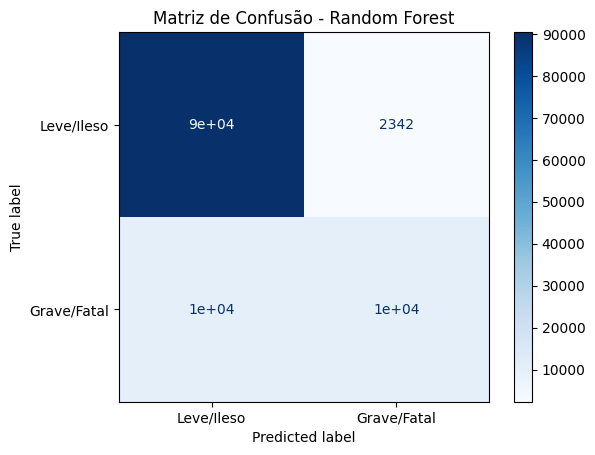

In [6]:

cm = confusion_matrix(
    y_test,
    rf_pred,
    labels=['Leve/Ileso', 'Grave/Fatal']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Leve/Ileso', 'Grave/Fatal']
)

disp.plot(cmap='Blues')
plt.title('Matriz de Confusão - Random Forest')
plt.show()


In [8]:
print(cm)

[[90429  2342]
 [10477 10339]]


In [7]:

indice_grave = list(rf.classes_).index('Grave/Fatal')

probabilidades = rf.predict_proba(X_test)[:, indice_grave]

auc = roc_auc_score(
    (y_test == 'Grave/Fatal').astype(int),
    probabilidades
)

print(f"AUC: {auc:.4f}")


AUC: 0.9180


### Análise dos resultados — Random Forest

O modelo Random Forest foi desenvolvido utilizando 100 árvores de decisão, com divisão de 75% dos dados para treinamento e 25% para teste.

Após a execução, o modelo apresentou acurácia de 88,71% e AUC de 0,9180.

Na matriz de confusão, foram identificados 90.429 acertos na classe Leve/Ileso e 10.339 acertos na classe Grave/Fatal.

Entretanto, o modelo apresentou maior dificuldade na identificação dos acidentes graves ou fatais, classificando incorretamente 10.477 registros dessa categoria como leves ou ilesos.

Conclui-se que o modelo apresentou bom desempenho geral, mas ainda possui limitações na identificação dos acidentes de maior gravidade.